In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv(r"C:\Users\DEEPA\Downloads\sp500_snapshot_2026-10-03.csv")

In [5]:
df.head()

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings
0,MMM,3M,Industrial Conglomerates,161.89,28.806050,0.0191,5.62,139.34,184.90,8.349031e+10,6.488000e+09,3.315739,28.282670,http://www.sec.gov/cgi-bin/browse-edgar?action...
1,AOS,A. O. Smith,Building Products,56.75,15.807800,0.0254,3.59,54.16,81.87,7.712812e+09,7.837000e+08,2.027073,4.187574,http://www.sec.gov/cgi-bin/browse-edgar?action...
2,ABT,Abbott Laboratories,Health Care Equipment,97.50,31.553398,0.0261,3.09,81.97,135.37,1.698268e+11,1.168100e+10,3.645525,3.300945,http://www.sec.gov/cgi-bin/browse-edgar?action...
3,ABBV,AbbVie,Biotechnology,262.82,74.242940,0.0266,3.54,190.75,269.39,4.644338e+11,3.076300e+10,7.213273,-78.243530,http://www.sec.gov/cgi-bin/browse-edgar?action...
4,ACN,Accenture,IT Consulting & Other Services,198.90,15.873902,0.0307,12.53,118.15,291.09,1.217153e+11,1.406878e+10,1.640734,3.816120,http://www.sec.gov/cgi-bin/browse-edgar?action...


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Symbol          503 non-null    object 
 1   Name            503 non-null    object 
 2   Sector          503 non-null    object 
 3   Price           486 non-null    float64
 4   Price/Earnings  458 non-null    float64
 5   Dividend Yield  399 non-null    float64
 6   Earnings/Share  486 non-null    float64
 7   52 Week Low     486 non-null    float64
 8   52 Week High    486 non-null    float64
 9   Market Cap      486 non-null    float64
 10  EBITDA          459 non-null    float64
 11  Price/Sales     485 non-null    float64
 12  Price/Book      486 non-null    float64
 13  SEC Filings     503 non-null    object 
dtypes: float64(10), object(4)
memory usage: 55.1+ KB


# 1. List out the unique Sector values in the dataset (there's a "Sector" column) — this shows  what industries are available.

In [7]:
df['Sector'].unique()

array(['Industrial Conglomerates', 'Building Products',
       'Health Care Equipment', 'Biotechnology',
       'IT Consulting & Other Services', 'Application Software',
       'Semiconductors', 'Independent Power Producers & Energy Traders',
       'Life & Health Insurance', 'Life Sciences Tools & Services',
       'Industrial Gases', 'Hotels, Resorts & Cruise Lines',
       'Internet Services & Infrastructure', 'Specialty Chemicals',
       'Office REITs', 'Health Care Supplies', 'Electric Utilities',
       'Property & Casualty Insurance', 'Interactive Media & Services',
       'Tobacco', 'Broadline Retail',
       'Paper & Plastic Packaging Products & Materials',
       'Diversified Support Services', 'Multi-Utilities',
       'Consumer Finance', 'Multi-line Insurance', 'Telecom Tower REITs',
       'Water Utilities', 'Asset Management & Custody Banks',
       'Electrical Components & Equipment', 'Electronic Components',
       'Insurance Brokers', 'Oil & Gas Exploration & Producti

In [8]:
#count per sector
len(df.groupby('Sector'))

127

In [9]:
df.groupby('Sector').nunique()

,Symbol,Name,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings
Sector,,,,,,,,,,,,,
Advertising,2,2,1,1,1,1,1,1,1,1,1,1,2
Aerospace & Defense,12,12,12,12,9,12,12,12,12,12,12,12,12
Agricultural & Farm Machinery,1,1,1,1,1,1,1,1,1,1,1,1,1
Agricultural Products & Services,2,2,2,2,2,2,2,2,2,2,2,2,2
Air Freight & Logistics,4,4,4,4,4,4,4,4,4,4,4,4,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Tobacco,2,2,2,2,2,2,2,2,2,2,2,2,2
Trading Companies & Distributors,2,2,2,2,2,2,2,2,2,2,2,2,2
Transaction & Payment Processing Services,8,8,7,7,6,7,7,7,7,7,7,7,8


In [10]:
#count of companies per sector
df.groupby('Sector')['Name'].nunique().sort_values(ascending=False)

Sector
Health Care Equipment                           18
Semiconductors                                  15
Electric Utilities                              15
Industrial Machinery & Supplies & Components    14
Packaged Foods & Meats                          12
                                                ..
Passenger Ground Transportation                  1
Food Retail                                      1
Food Distributors                                1
Data Processing & Outsourced Services            1
Wireless Telecommunication Services              1
Name: Name, Length: 127, dtype: int64

In [11]:
df.groupby('Sector')['Name'].apply(list)

Sector
Advertising                                  [Interpublic Group of Companies (The), Omnicom...
Aerospace & Defense                          [Axon Enterprise, Boeing, GE Aerospace, Genera...
Agricultural & Farm Machinery                                                [Deere & Company]
Agricultural Products & Services                        [Archer Daniels Midland, Bunge Global]
Air Freight & Logistics                      [C.H. Robinson, Expeditors International, FedE...
                                                                   ...                        
Tobacco                                                  [Altria, Philip Morris International]
Trading Companies & Distributors                                    [Fastenal, United Rentals]
Transaction & Payment Processing Services    [Corpay, Fidelity National Information Service...
Water Utilities                                                         [American Water Works]
Wireless Telecommunication Services        

# Step 1: Filter to mid-cap companies


In [12]:
mid_cap= df[
    (df['Market Cap']>=2_000_000_000) &
    (df['Market Cap']<=10_000_000_000)
    ]

In [13]:
mid_cap.head()

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings
1,AOS,A. O. Smith,Building Products,56.75,15.807800,0.0254,3.59,54.16,81.87,7.712812e+09,7.837000e+08,2.027073,4.187574,http://www.sec.gov/cgi-bin/browse-edgar?action...
14,ARE,Alexandria Real Estate Equities,Office REITs,47.37,NaN,0.0612,-6.05,39.41,84.30,8.152153e+09,1.781941e+09,2.870146,0.519961,http://www.sec.gov/cgi-bin/browse-edgar?action...
24,AMTM,Amentum,Diversified Support Services,18.14,21.855421,NaN,0.83,17.72,38.11,4.435346e+09,1.006000e+09,0.313896,0.943956,http://www.sec.gov/cgi-bin/browse-edgar?action...
41,APTV,Aptiv,Automotive Parts & Equipment,43.54,19.701357,NaN,2.21,42.56,88.93,9.213958e+09,3.233000e+09,0.449067,1.036469,http://www.sec.gov/cgi-bin/browse-edgar?action...
76,BLDR,Builders FirstSource,Building Products,56.25,61.141304,NaN,0.92,54.75,131.50,6.052301e+09,1.022512e+09,0.418882,1.511081,http://www.sec.gov/cgi-bin/browse-edgar?action...


In [14]:
len(mid_cap)

37

In [15]:
#filter further by EBITDA where its not null
mid_cap_df=mid_cap[mid_cap['EBITDA'].notna()]

In [16]:
mid_cap_df[['Symbol','Name','Sector','EBITDA']].head()

,Symbol,Name,Sector,EBITDA
1,AOS,A. O. Smith,Building Products,7.837000e+08
14,ARE,Alexandria Real Estate Equities,Office REITs,1.781941e+09
24,AMTM,Amentum,Diversified Support Services,1.006000e+09
41,APTV,Aptiv,Automotive Parts & Equipment,3.233000e+09
76,BLDR,Builders FirstSource,Building Products,1.022512e+09


In [17]:
mid_cap_df['Name'].nunique()

36

In [18]:
#the full list of sectors available in mid-cap group, with counts
mid_cap_df.groupby('Sector')['Name'].nunique().sort_values(ascending=False)

Sector
Casinos & Gaming                                3
Packaged Foods & Meats                          3
Specialty Chemicals                             2
Building Products                               2
Distributors                                    2
Financial Exchanges & Data                      2
Health Care Equipment                           2
Automotive Parts & Equipment                    1
Industrial Machinery & Supplies & Components    1
Semiconductor Materials & Equipment             1
Retail REITs                                    1
Restaurants                                     1
Office REITs                                    1
Multi-Family Residential REITs                  1
Managed Health Care                             1
Interactive Media & Services                    1
Household Products                              1
IT Consulting & Other Services                  1
Human Resource & Employment Services            1
Automotive Retail                          

### To find the best companies in the portfolio

### The data set gives us EBITDA & Price/Sales but no Sales/rev info is given so we work backward.
- find Established Sales 
- find EBITDA Margin

#### a. Create a column sales_est(estimated Sales) = Market Cap ÷ Price/Sales (this backs out an implied revenue figure)

In [19]:
df['Sales_est']=df['Market Cap']/df['Price/Sales']

#### b. Create a column ebitda_margin = EBITDA ÷ sales_est

In [20]:
df['EBITDA_Margin']= df['EBITDA']/df['Sales_est']

In [21]:
df.head()

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings,Sales_est,EBITDA_Margin
0,MMM,3M,Industrial Conglomerates,161.89,28.806050,0.0191,5.62,139.34,184.90,8.349031e+10,6.488000e+09,3.315739,28.282670,http://www.sec.gov/cgi-bin/browse-edgar?action...,2.518000e+10,0.257665
1,AOS,A. O. Smith,Building Products,56.75,15.807800,0.0254,3.59,54.16,81.87,7.712812e+09,7.837000e+08,2.027073,4.187574,http://www.sec.gov/cgi-bin/browse-edgar?action...,3.804900e+09,0.205971
2,ABT,Abbott Laboratories,Health Care Equipment,97.50,31.553398,0.0261,3.09,81.97,135.37,1.698268e+11,1.168100e+10,3.645525,3.300945,http://www.sec.gov/cgi-bin/browse-edgar?action...,4.658500e+10,0.250746
3,ABBV,AbbVie,Biotechnology,262.82,74.242940,0.0266,3.54,190.75,269.39,4.644338e+11,3.076300e+10,7.213273,-78.243530,http://www.sec.gov/cgi-bin/browse-edgar?action...,6.438600e+10,0.477790
4,ACN,Accenture,IT Consulting & Other Services,198.90,15.873902,0.0307,12.53,118.15,291.09,1.217153e+11,1.406878e+10,1.640734,3.816120,http://www.sec.gov/cgi-bin/browse-edgar?action...,7.418344e+10,0.189649


### 2. Apply the mid-cap filter

In [22]:
df_mid_cap_cos= df[
    (df['Market Cap']>=2_000_000_000) &
    (df['Market Cap']<=10_000_000_000)
    ]

In [23]:
filtered_mid_cap_cos=df_mid_cap_cos[df_mid_cap_cos['EBITDA'].notna()]

In [24]:
filtered_mid_cap_cos.nunique()

Symbol            36
Name              36
Sector            27
Price             36
Price/Earnings    29
Dividend Yield    23
Earnings/Share    35
52 Week Low       36
52 Week High      36
Market Cap        36
EBITDA            36
Price/Sales       36
Price/Book        36
SEC Filings       36
Sales_est         36
EBITDA_Margin     36
dtype: int64

### 3.Apply the quality/stability screen — all of these conditions together


#### Filter further to keep only rows where:

- ebitda_margin is 0.15 or higher (15%+)
- Dividend Yield is greater than 0 (i.e., it actually pays a dividend)
- Price/Earnings is greater than 0 and less than or equal to 30
- Also check Price/Sales is greater than 0 (avoids a divide-by-zero or negative-sales problem in Step 1)



In [25]:
screened_df=filtered_mid_cap_cos[
            (filtered_mid_cap_cos['EBITDA_Margin']>=0.15) &
            (filtered_mid_cap_cos['Dividend Yield']>0) &
            (filtered_mid_cap_cos['Price/Earnings'] > 0) &
            (filtered_mid_cap_cos['Price/Earnings'] <= 30)&
            (filtered_mid_cap_cos['Price/Sales']>0)
    ]
             

In [27]:
len(screened_df)

14

In [28]:
screened_df.head(14)

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings,Sales_est,EBITDA_Margin
1,AOS,A. O. Smith,Building Products,56.750,15.807800,0.0254,3.59,54.16,81.870,7.712812e+09,7.837000e+08,2.027073,4.187574,http://www.sec.gov/cgi-bin/browse-edgar?action...,3.804900e+09,0.205971
83,CPB,Campbell Soup Company,Packaged Foods & Meats,19.620,14.977100,0.0513,1.31,19.10,32.090,5.851365e+09,1.620000e+09,0.600510,1.518693,http://www.sec.gov/cgi-bin/browse-edgar?action...,9.744000e+09,0.166256
112,CLX,Clorox,Household Products,80.410,16.717257,0.0620,4.81,79.12,128.900,9.724063e+09,1.140000e+09,1.447033,108.077960,http://www.sec.gov/cgi-bin/browse-edgar?action...,6.720000e+09,0.169643
154,DPZ,Domino's,Restaurants,297.615,16.871600,0.0270,17.64,282.00,442.350,9.845621e+09,1.023514e+09,1.958230,-2.471311,http://www.sec.gov/cgi-bin/browse-edgar?action...,5.027815e+09,0.203570
160,EMN,Eastman Chemical Company,Specialty Chemicals,64.870,17.116096,0.0525,3.79,56.11,83.470,7.416369e+09,1.393000e+09,0.836590,1.216594,http://www.sec.gov/cgi-bin/browse-edgar?action...,8.865001e+09,0.157135
189,FDS,FactSet,Financial Exchanges & Data,266.000,18.256693,0.0167,14.57,185.00,320.480,9.460435e+09,8.807870e+08,3.820459,4.682769,http://www.sec.gov/cgi-bin/browse-edgar?action...,2.476256e+09,0.355693
192,FRT,Federal Realty Investment Trust,Retail REITs,106.690,21.553537,0.0430,4.95,90.03,128.210,9.273325e+09,8.377010e+08,6.944110,2.892504,http://www.sec.gov/cgi-bin/browse-edgar?action...,1.335423e+09,0.627293
265,JKHY,Jack Henry & Associates,Transaction & Payment Processing Services,142.540,20.450502,0.0170,6.97,121.04,193.390,9.993851e+09,7.022140e+08,3.927877,4.867504,http://www.sec.gov/cgi-bin/browse-edgar?action...,2.544339e+09,0.275991
286,LW,Lamb Weston,Packaged Foods & Meats,43.600,20.961538,0.0369,2.08,37.62,67.070,5.994265e+09,1.104300e+09,0.906533,3.284121,http://www.sec.gov/cgi-bin/browse-edgar?action...,6.612300e+09,0.167007
302,MKTX,MarketAxess,Financial Exchanges & Data,164.140,19.401892,0.0190,8.46,108.75,195.970,5.777268e+09,4.349560e+08,6.640346,4.662406,http://www.sec.gov/cgi-bin/browse-edgar?action...,8.700250e+08,0.499935


#### 4. Sort and inspect

In [29]:
# Sort screened_df by ebitda_margin, highest first, and display the columns: Symbol, Name, Sector, Market Cap, ebitda_margin, Dividend Yield, Price/Earnings.

screened_df.sort_values(
    by='EBITDA_Margin',
    ascending=False)[['Symbol',
    'Name',
    'Sector',
    'Market Cap',
    'EBITDA_Margin',
    'Dividend Yield',
    'Price/Earnings'
]]

,Symbol,Name,Sector,Market Cap,EBITDA_Margin,Dividend Yield,Price/Earnings
192,FRT,Federal Realty Investment Trust,Retail REITs,9.273325e+09,0.627293,0.0430,21.553537
302,MKTX,MarketAxess,Financial Exchanges & Data,5.777268e+09,0.499935,0.0190,19.401892
189,FDS,FactSet,Financial Exchanges & Data,9.460435e+09,0.355693,0.0167,18.256693
368,PAYC,Paycom,Human Resource & Employment Services,9.960377e+09,0.343392,0.0066,23.360466
308,MTCH,Match Group,Interactive Media & Services,9.255496e+09,0.338792,0.0199,14.297873
265,JKHY,Jack Henry & Associates,Transaction & Payment Processing Services,9.993851e+09,0.275991,0.0170,20.450502
370,PNR,Pentair,Industrial Machinery & Supplies & Components,8.569942e+09,0.257939,0.0204,13.667525
496,WYNN,Wynn Resorts,Casinos & Gaming,7.813658e+09,0.244007,0.0129,18.196642
1,AOS,A. O. Smith,Building Products,7.712812e+09,0.205971,0.0254,15.807800
154,DPZ,Domino's,Restaurants,9.845621e+09,0.203570,0.0270,16.871600


### Fund Thesis
The final 14 holdings are chosen by rule based selection process which includes 
-  Mid-Cap Sizing(USD 2B to USD 10B), large enough to generate stable, predictable cash flow to support leverage, but small enough to be realistically acquired and actively managed by a mid-market buyout fund
- EBITDA margin >= 15%, For operational efficiency and cash-generation quality
- Positive dividend yield(mature, stable cash-flow businesses) signals a mature, stable cash-flow business rather than a speculative growth story reinvesting all earnings
- & a disciplined P/E ratio <=30% to avoid speculative pricing.This is done so as to  avoid companies whose stock price is expensive compared to what they're actually earning right now. We need to see the proof of profit , not just the promise of it.

### Assumptions & Limitations.
### This project uses real public company data as a proxy for private equity portfolio monitoring, since actual PE deal data is confidential. Several simplifying assumptions were made:

- Entry price is approximated using each company's 52-week low, standing in for a hypothetical acquisition price. A real acquisition price is negotiated and typically includes a premium over market price.
- Position size/investment amount is approximated using Market Cap, assuming a full (100%) acquisition of each company. This does not account for leverage (debt financing) — in a real buyout, the PE fund typically funds only 50–70% of the purchase price in equity, borrowing the rest against the target company's own assets and cash flows. This means real-world equity returns on a successful deal would typically be higher than shown here, since actual fund capital deployed would be smaller than the full "purchase price."
- EV/EBITDA-style multiples use Market Cap ÷ EBITDA rather than true Enterprise Value ÷ EBITDA, since debt and cash figures aren't available in this dataset.
- This analysis uses data from a single date, not quarterly history, so it can't show how the holdings change over time as real portfolio monitoring would.
- These are public companies with many shareholders. For simplicity, the fund is assumed to own 100% of each company, and no real ownership or control percentages are modelled.

In [28]:
screened_df.head()

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings,Sales_est,EBITDA_Margin
1,AOS,A. O. Smith,Building Products,56.750,15.807800,0.0254,3.59,54.16,81.87,7.712812e+09,7.837000e+08,2.027073,4.187574,http://www.sec.gov/cgi-bin/browse-edgar?action...,3.804900e+09,0.205971
83,CPB,Campbell Soup Company,Packaged Foods & Meats,19.620,14.977100,0.0513,1.31,19.10,32.09,5.851365e+09,1.620000e+09,0.600510,1.518693,http://www.sec.gov/cgi-bin/browse-edgar?action...,9.744000e+09,0.166256
112,CLX,Clorox,Household Products,80.410,16.717257,0.0620,4.81,79.12,128.90,9.724063e+09,1.140000e+09,1.447033,108.077960,http://www.sec.gov/cgi-bin/browse-edgar?action...,6.720000e+09,0.169643
154,DPZ,Domino's,Restaurants,297.615,16.871600,0.0270,17.64,282.00,442.35,9.845621e+09,1.023514e+09,1.958230,-2.471311,http://www.sec.gov/cgi-bin/browse-edgar?action...,5.027815e+09,0.203570
160,EMN,Eastman Chemical Company,Specialty Chemicals,64.870,17.116096,0.0525,3.79,56.11,83.47,7.416369e+09,1.393000e+09,0.836590,1.216594,http://www.sec.gov/cgi-bin/browse-edgar?action...,8.865001e+09,0.157135


In [30]:
screened_df = filtered_mid_cap_cos[
    (filtered_mid_cap_cos['EBITDA_Margin'] >= 0.15) &
    (filtered_mid_cap_cos['Dividend Yield'] > 0) &
    (filtered_mid_cap_cos['Price/Earnings'] > 0) &
    (filtered_mid_cap_cos['Price/Earnings'] <= 30) &
    (filtered_mid_cap_cos['Price/Sales'] > 0)
].copy()

### Build the implied return Multiple on Invested Capital(MOIC) 
MOIC measures the total value of private equity investment relative to its initial cost, also called the equity multiple/cash on cash multiple.

In [31]:
# create entry_price=52 week low. This stands in for the price your fund "paid" when it acquired the stake.
screened_df['entry_price']= screened_df['52 Week Low']

In [32]:
#create current_price=screened_df['Price']
screened_df['current_price']=screened_df['Price']

In [33]:
screened_df['implied_return_pct'] = (
    (screened_df['current_price'] - screened_df['entry_price'])
    / screened_df['entry_price']
) * 100

In [34]:
screened_df['MOIC']=screened_df['current_price']/screened_df['entry_price']

In [35]:
portfolio=screened_df.sort_values(
    by='MOIC', ascending=False)
portfolio.head(13)

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings,Sales_est,EBITDA_Margin,entry_price,current_price,implied_return_pct,MOIC
368,PAYC,Paycom,Human Resource & Employment Services,220.990,23.360466,0.0066,9.46,104.90,244.980,9.960377e+09,7.351000e+08,4.652860,16.820673,http://www.sec.gov/cgi-bin/browse-edgar?action...,2.140700e+09,0.343392,104.90,220.990,110.667302,2.106673
302,MKTX,MarketAxess,Financial Exchanges & Data,164.140,19.401892,0.0190,8.46,108.75,195.970,5.777268e+09,4.349560e+08,6.640346,4.662406,http://www.sec.gov/cgi-bin/browse-edgar?action...,8.700250e+08,0.499935,108.75,164.140,50.933333,1.509333
189,FDS,FactSet,Financial Exchanges & Data,266.000,18.256693,0.0167,14.57,185.00,320.480,9.460435e+09,8.807870e+08,3.820459,4.682769,http://www.sec.gov/cgi-bin/browse-edgar?action...,2.476256e+09,0.355693,185.00,266.000,43.783784,1.437838
308,MTCH,Match Group,Interactive Media & Services,40.320,14.297873,0.0199,2.82,28.81,44.935,9.255496e+09,1.188930e+09,2.637404,-39.107662,http://www.sec.gov/cgi-bin/browse-edgar?action...,3.509320e+09,0.338792,28.81,40.320,39.951406,1.399514
192,FRT,Federal Realty Investment Trust,Retail REITs,106.690,21.553537,0.0430,4.95,90.03,128.210,9.273325e+09,8.377010e+08,6.944110,2.892504,http://www.sec.gov/cgi-bin/browse-edgar?action...,1.335423e+09,0.627293,90.03,106.690,18.504943,1.185049
265,JKHY,Jack Henry & Associates,Transaction & Payment Processing Services,142.540,20.450502,0.0170,6.97,121.04,193.390,9.993851e+09,7.022140e+08,3.927877,4.867504,http://www.sec.gov/cgi-bin/browse-edgar?action...,2.544339e+09,0.275991,121.04,142.540,17.762723,1.177627
286,LW,Lamb Weston,Packaged Foods & Meats,43.600,20.961538,0.0369,2.08,37.62,67.070,5.994265e+09,1.104300e+09,0.906533,3.284121,http://www.sec.gov/cgi-bin/browse-edgar?action...,6.612300e+09,0.167007,37.62,43.600,15.895800,1.158958
160,EMN,Eastman Chemical Company,Specialty Chemicals,64.870,17.116096,0.0525,3.79,56.11,83.470,7.416369e+09,1.393000e+09,0.836590,1.216594,http://www.sec.gov/cgi-bin/browse-edgar?action...,8.865001e+09,0.157135,56.11,64.870,15.612190,1.156122
154,DPZ,Domino's,Restaurants,297.615,16.871600,0.0270,17.64,282.00,442.350,9.845621e+09,1.023514e+09,1.958230,-2.471311,http://www.sec.gov/cgi-bin/browse-edgar?action...,5.027815e+09,0.203570,282.00,297.615,5.537234,1.055372
1,AOS,A. O. Smith,Building Products,56.750,15.807800,0.0254,3.59,54.16,81.870,7.712812e+09,7.837000e+08,2.027073,4.187574,http://www.sec.gov/cgi-bin/browse-edgar?action...,3.804900e+09,0.205971,54.16,56.750,4.782127,1.047821


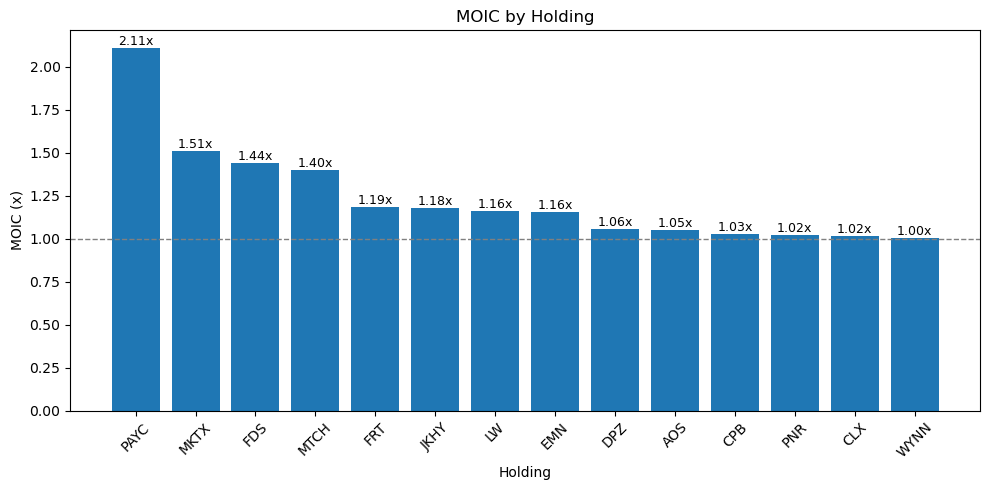

In [62]:
plot_df = portfolio.sort_values('MOIC', ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(plot_df['Symbol'], plot_df['MOIC'])

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{bar.get_height():.2f}x', ha='center', va='bottom', fontsize=9)

plt.axhline(1.0, linestyle='--', linewidth=1, color='gray')   # break-even line

plt.xlabel('Holding')
plt.ylabel('MOIC (x)')
plt.title('MOIC by Holding')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('moic_by_company.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

<Figure size 640x480 with 0 Axes>

### Interpretation
- Top performer, Paycom, with a MOIC of 2.1X, is from the Human Resources & Employment Services sector. MarketAxess (1.5X) and FactSet (1.44X), both from the Financial Exchanges & Data sector, form the next strongest cluster — close in performance, though not identical.
- Mid-range performers are Eastman Chemical Co., Lamb Weston, A.O. Smith, Domino's, Federal Realty, and Jack Henry & Associates, with MOIC ranging from roughly 1.19X down to 1.05X, showing steady gains.
- Weak performers are Pentair, Campbell Soup Co., and Clorox, all close to flat at roughly 1.02X–1.03X.
- Please note: because entry price is defined as the 52-week low, positive returns across the portfolio are partly a function of this methodology rather than purely investment skill — a real fund's entry price would be a negotiated acquisition price, not a market low.

In [38]:
# Calculate the Simple Avg MOIC
Simple_AVG_MOIC=round(screened_df['MOIC'].mean(),2)
print(f'Simple Average MOIC:{Simple_AVG_MOIC}')

Simple Average MOIC:1.24


#### If we treated every company in the portfolio equally, then it would have delivered an overall return of 24 % since entry.

In [39]:
# Calculate Weighetd Average MOIC

# Create column Weighted_contribution
screened_df['weighted_contribution']=screened_df['MOIC']*screened_df['Market Cap']

In [40]:
#sum of all weighted_contribution
Sum_Weighted_Contribution=screened_df['weighted_contribution'].sum()
print(f'Sum_Weighetd_Contribution:{Sum_Weighted_Contribution}')

Sum_Weighetd_Contribution:145503085786.24384


In [41]:
# Total Market Cap
Total_Market_Cap=screened_df['Market Cap'].sum()
print(f'Total_Market_Cap :{Total_Market_Cap}')

Total_Market_Cap :116648844288.0


In [42]:
Weighted_Average_Moic=round((Sum_Weighted_Contribution/Total_Market_Cap),2)
print(f'Weighted_Average_MOIC:{Weighted_Average_Moic}')

Weighted_Average_MOIC:1.25


#### Interpretation
- The Weighted Average MOIC (1.25x) is very slightly higher than the Simple Average MOIC (1.24x). This small gap suggests that, on balance, the larger-market-cap holdings in the portfolio are performing marginally better than the smaller ones — enough to pull the capital-weighted average slightly above the simple average. The difference remains small, which still points to a reasonably balanced portfolio by position size: no single holding is large enough to meaningfully distort the fund's overall performance in either direction.

- Note:- Paycom's outsized MOIC (2.11x) is the significant driver of the fund's overall blended performance, emphasizing how a single strong performer can meaningfully shift fund-level averages even in a diversified portfolio. This suggests that it's useful  to monitor individual holding performance, not just overall fund metrics, in practice.

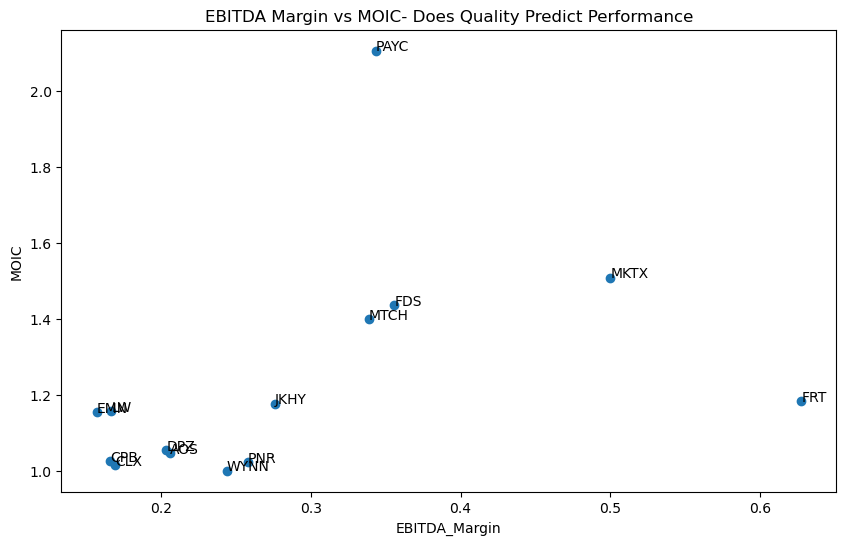

In [43]:
plt.figure(figsize=(10,6))
plt.scatter(screened_df['EBITDA_Margin'],screened_df['MOIC'])

for i,symbol in enumerate (screened_df['Symbol']):
    plt.annotate(
        symbol,
        (screened_df['EBITDA_Margin'].iloc[i],
         screened_df['MOIC'].iloc[i])
    )
    
    
plt.xlabel('EBITDA_Margin')
plt.ylabel('MOIC')
plt.title('EBITDA Margin vs MOIC- Does Quality Predict Performance')
plt.show()

In [44]:
!pip install adjustText

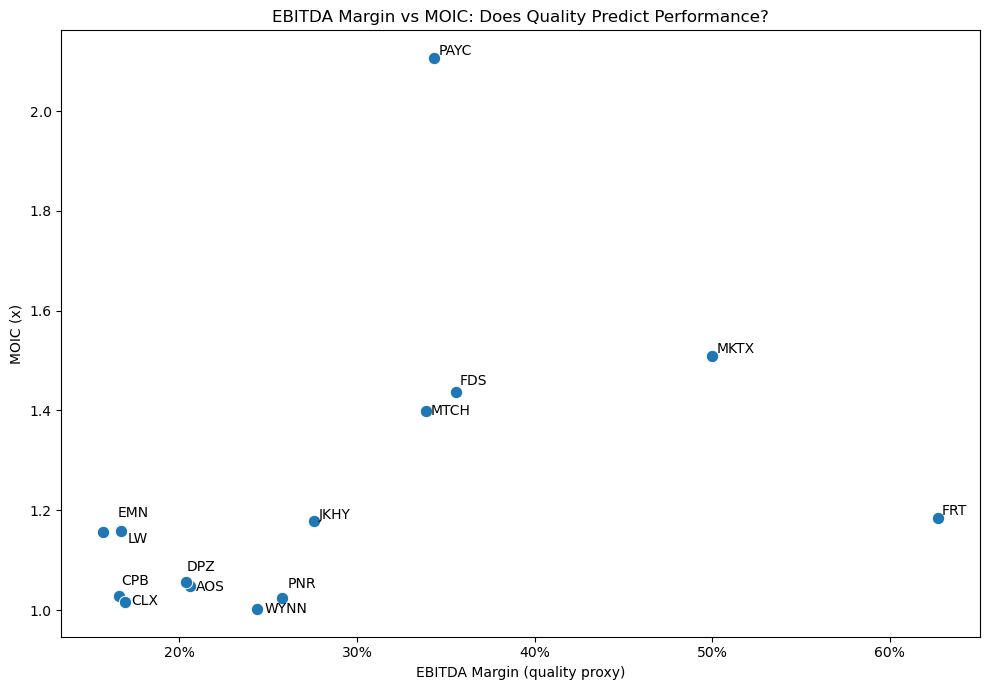

In [61]:
import seaborn as sns
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(10, 7))

sns.scatterplot(data=screened_df, x='EBITDA_Margin', y='MOIC', s=80)

texts = []
for i, symbol in enumerate(screened_df['Symbol']):
    texts.append(plt.text(screened_df['EBITDA_Margin'].iloc[i],
                          screened_df['MOIC'].iloc[i], symbol))
adjust_text(texts)

plt.gca().xaxis.set_major_formatter(PercentFormatter(1.0))   # 0.35 shows as 35%
plt.xlabel('EBITDA Margin (quality proxy)')
plt.ylabel('MOIC (x)')
plt.title('EBITDA Margin vs MOIC: Does Quality Predict Performance?')
plt.tight_layout()
plt.savefig('ebitda_margin_vs_moic.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()



### Interpretation
- Nine of the 14 holdings having EBITDA below 30% returned MOIC of 1.0X and 1.2X
- Of the 5 Holdings above 30% EBITDA, four (Paycon, MarketAxess, FactSet, Match Group )returned 1.4X or more. The exception is FRT(Federal Realty Investment Trust), which has the highest margin of more than 60% EBITDA  and modest returns matching 1.2X
- This suggests higher-margin businesses tended to perform better, but it's just a one-time reading with only 14 holdings, so it's just an indication, not proof of performance.

## Average MOIC by Sector visulaized

In [48]:
# Calculate Average MOIC by sector
Avg_MOIC_by_sector=screened_df.groupby('Sector')['MOIC'].mean().sort_values()
print(Avg_MOIC_by_sector)

Sector
Casinos & Gaming                                1.001716
Household Products                              1.016304
Industrial Machinery & Supplies & Components    1.023548
Building Products                               1.047821
Restaurants                                     1.055372
Packaged Foods & Meats                          1.093092
Specialty Chemicals                             1.156122
Transaction & Payment Processing Services       1.177627
Retail REITs                                    1.185049
Interactive Media & Services                    1.399514
Financial Exchanges & Data                      1.473586
Human Resource & Employment Services            2.106673
Name: MOIC, dtype: float64


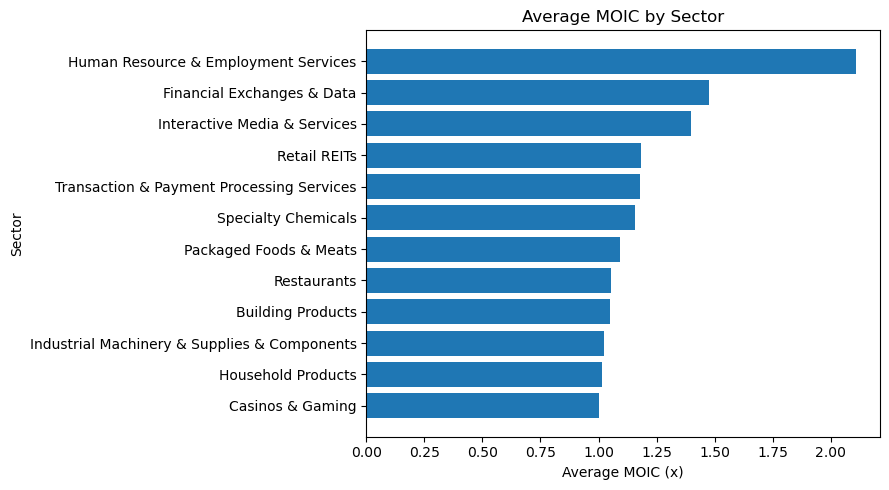

In [60]:
sector_sorted = Avg_MOIC_by_sector.sort_values()   # lowest at bottom, highest at top

plt.figure(figsize=(9, 5))
plt.barh(sector_sorted.index, sector_sorted.values)

plt.xlabel('Average MOIC (x)')
plt.ylabel('Sector')
plt.title('Average MOIC by Sector')
plt.tight_layout()
plt.savefig('avg_moic_by_sector.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()


<Figure size 640x480 with 0 Axes>

### Interpretation
- Average implied MOIC varies across the sectors in the portfolio held. Human Resource & Employment Services shows the highest at 2.11x, followed by Financial Exchanges & Data at 1.47x and Interactive Media & Services at 1.40x. At the lower end, Casinos & Gaming, Household Products, and Industrial Machinery & Supplies & Components are close to 1.0x, indicating limited price appreciation from the assumed entry point.
- These sector level analysis must be read with caution as several sectors contain one or two holdings , so the average displays a single company. For eg Human resources & employement services is driven entirely by Paycon and Interactive Media & services by Match Group alone.
- In addition, MOIC here is measured from a 52-week-low entry price, which flatters all returns. The analysis therefore describes how this particular portfolio performed on a point-in-time basis. It does not show that any sector will outperform in future.

### Simple AVG MOIC vs. Weighted Average MOIC

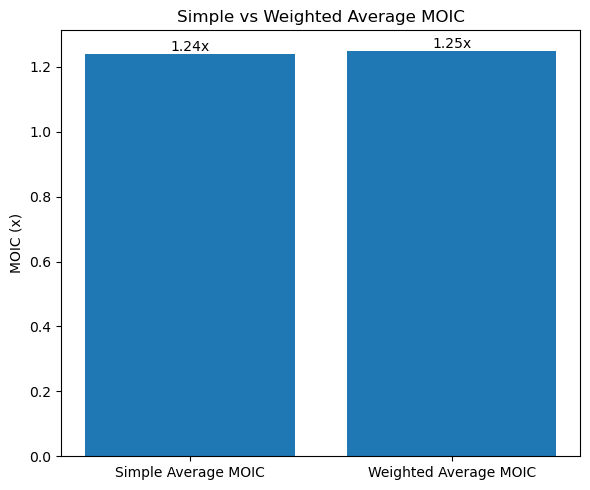

In [59]:
plt.figure(figsize=(6, 5))
bars = plt.bar(['Simple Average MOIC', 'Weighted Average MOIC'],
               [Simple_AVG_MOIC, Weighted_Average_Moic])

# put the value on top of each bar
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{bar.get_height():.2f}x', ha='center', va='bottom')

plt.ylabel('MOIC (x)')
plt.title('Simple vs Weighted Average MOIC')
plt.tight_layout()
plt.savefig('simple_vs_weighted_moic.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

# Interpretation
- Simple Average MOIC is 1.24X, while the market-cap-Weighted Average MOIC is slightly higher at 1.25x. The small difference suggest that larger companies in the screened portfolio have marginally stronger returns than smaller companies.However, the difference is minimal, indicating that market capitalization does not materially change the overall returns.

# Distance from 52-week high

In [53]:
screened_df['dist_from_high_pct'] = round((
    (screened_df['52 Week High'] - screened_df['Price'])
    / screened_df['52 Week High']
) * 100,0)

In [54]:
#  Sort from furthest below the high to closest to the high
sorted_df = screened_df.sort_values(
    by='dist_from_high_pct',
    ascending=True
)


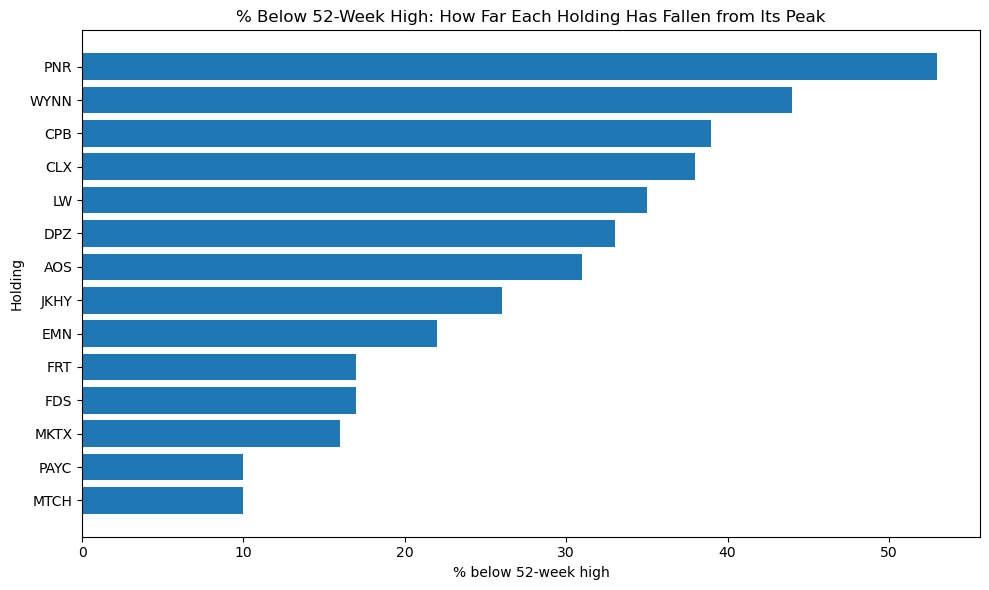

In [63]:
#  Horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(sorted_df['Symbol'], sorted_df['dist_from_high_pct'])

plt.axvline(0, linestyle='--', color='gray')   # 0 = at the 52-week high

plt.xlabel('% below 52-week high')
plt.ylabel('Holding')
plt.title('% Below 52-Week High: How Far Each Holding Has Fallen from Its Peak')
plt.tight_layout()
plt.savefig('distance_from_52w_high.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

In [58]:
plt.tight_layout()
plt.savefig('momentum_pct_below_52w_high.png', dpi=200, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

## Interpretation: Distance from the 52-Week High
The chart shows a wide variation in how far the companies trade below their 52 Weeks High


- Furthest from the 52 Week high are: PNR (Pentair which is about 55% below) and WYNN, about 45% below.
- Moderately far are:  CPB and CLX (about 37–38% below), and LW, DPZ, and AOS (about 30–35% below).
- Closest to the high: MTCH and PAYC (only about 9–10% below).
This is what the MOIC also tells: companies whose MOIC is above 1.4X or more (PAYC, MKTX, FDS, MTCH)are trading close to 20% of their 52 Week high, whereas compoanies with MOIC of 1X sits close to their 52 Week Lows.

A company can be 50% below its high because its fundamentals have deteriorated. Conversely, a company near its high may still be attractive if earnings and valuation support further upside. This measure describes price behaviour, not value, and should be read alongside fundamentals such as EBITDA margin and P/E.

